# SIS safety text analytics: walkthrough

Step-by-step run of the pipeline on the synthetic data, following the project stages: load data, clean text, link each narrative to a SIF, classify the initiating event, compare with the LOPA, evaluate.

*All data is synthetic. No plant data is used.*

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
pd.set_option('display.max_colwidth', 120)

## 1. Load the data
A SIF register, the LOPA scenarios behind each SIF, and the incident / shift-log narratives.

In [2]:
from src.data.load_data import load_data
reg, scen, narr, labels = load_data()
print(len(reg), 'SIFs |', len(scen), 'LOPA scenarios |', len(narr), 'narratives')
narr[['narrative_id','date','unit','text']].head(5)

240 SIFs | 487 LOPA scenarios | 440 narratives


,narrative_id,date,unit,text
0,N0001,2021-01-03,U50,"Operator opened bypass instead of block valve on IA receiver V-5104. pressure low alarm on the transmitter ackd, boa..."
1,N0002,2021-01-06,U50,"Outelt line plugged with solids, no flow from CW pump P-5103A. BPCS and operator response held flow below trip setpo..."
2,N0003,2021-01-13,U60,"sif-60-018 trpd with no process demand. impulse line of U60-LT-6018 plugged, reading false. Restarted after 18 hrs."
3,N0004,2021-01-19,U60,"Process deviation, root cause not yet recorded. BPCS and optr response held lvl below trip setpoint; sif-60-021 did ..."
4,N0005,2021-01-22,U60,"SIF60035 tripped with no process demand. loose terminal on u60-pt-6035 loop wiring, no process deviation. Restarted ..."


## 2. Clean the text
Field shorthand is expanded so the same event reads the same way.

In [3]:
from src.data.preprocess import clean
for t in narr.text.head(3):
    print('RAW  :', t)
    print('CLEAN:', clean(t), '\n')

RAW  : Operator opened bypass instead of block valve on IA receiver V-5104. pressure low alarm on the transmitter ackd, board optr opened bypass to restore flow; the SIF not demanded.
CLEAN: operator opened bypass instead of block valve on instrument air receiver v-5104. pressure low alarm on the transmitter acknowledged, board operator opened bypass to restore flow; the sif not demanded. 

RAW  : Outelt line plugged with solids, no flow from CW pump P-5103A. BPCS and operator response held flow below trip setpoint; SIF50030 did not act. No pump trip recorded.
CLEAN: outelt line plugged with solids, no flow from cooling water pump p-5103a. bpcs and operator response held flow below trip setpoint; sif50030 did not act. no pump trip recorded. 

RAW  : sif-60-018 trpd with no process demand. impulse line of U60-LT-6018 plugged, reading false. Restarted after 18 hrs.
CLEAN: sif-60-018 tripped with no process demand. impulse line of u60-lt-6018 plugged, reading false. restarted after 18 hrs

## 3. Link each narrative to a SIF
SIF ID first, then the instrument tag, then equipment + process variable. Anything ambiguous is sent for review.

In [4]:
from src.features.sif_linking import SifLinker
linker = SifLinker(reg)
for t, u in zip(narr.text.head(5), narr.unit.head(5)):
    print(linker.link(t, clean(t), u)[:2], '|', t[:90])

(None, 'unlinked') | Operator opened bypass instead of block valve on IA receiver V-5104. pressure low alarm on
('SIF-50-030', 'sif_id') | Outelt line plugged with solids, no flow from CW pump P-5103A. BPCS and operator response 
('SIF-60-018', 'sif_id') | sif-60-018 trpd with no process demand. impulse line of U60-LT-6018 plugged, reading false
('SIF-60-021', 'sif_id') | Process deviation, root cause not yet recorded. BPCS and optr response held lvl below trip
('SIF-60-035', 'sif_id') | SIF60035 tripped with no process demand. loose terminal on u60-pt-6035 loop wiring, no pro


## 4-6. Classify, link and compare with the LOPA (full pipeline)

In [5]:
from src import pipeline
tagged, scen_t, flags, years = pipeline.run()
flags

440 narratives over 4.99 yr | linked 84% | needs review 92 | flags 7


,finding,sif_id,ie_category,evidence
0,Initiating event more frequent than LOPA assumed,SIF-30-030,rotating_equipment_trip,19 events in 4.99 yr vs 2.50 expected (q=0.000)
1,Initiating event more frequent than LOPA assumed,SIF-20-019,loss_of_cooling,6 events in 4.99 yr vs 0.25 expected (q=0.000)
2,Initiating event more frequent than LOPA assumed,SIF-20-031,utility_loss,7 events in 4.99 yr vs 0.50 expected (q=0.000)
3,Initiating event more frequent than LOPA assumed,SIF-10-036,utility_loss,6 events in 4.99 yr vs 0.50 expected (q=0.002)
4,Initiating event more frequent than LOPA assumed,SIF-50-011,bpcs_loop_failure,6 events in 4.99 yr vs 1.00 expected (q=0.057)
5,Initiating event not in the SIF's LOPA,SIF-60-013,bpcs_loop_failure,"3 events: N0021, N0085, N0168"
6,Initiating event not in the SIF's LOPA,SIF-30-021,utility_loss,"2 events: N0152, N0276"


## 7. Evaluate against the synthetic ground truth

In [6]:
from src.models import evaluate
m = evaluate.run(tagged, scen_t, flags, years)
{k: v for k, v in m.items() if not isinstance(v, dict)}

{'narratives': 440,
 'classifier_macro_f1': 0.951,
 'classifier_accuracy': 0.964,
 'keyword_baseline_macro_f1': 0.555,
 'keyword_baseline_accuracy': 0.643,
 'outcome_accuracy': 1.0,
 'link_coverage': 0.843,
 'link_precision': np.float64(0.995),
 'needs_review': 92}

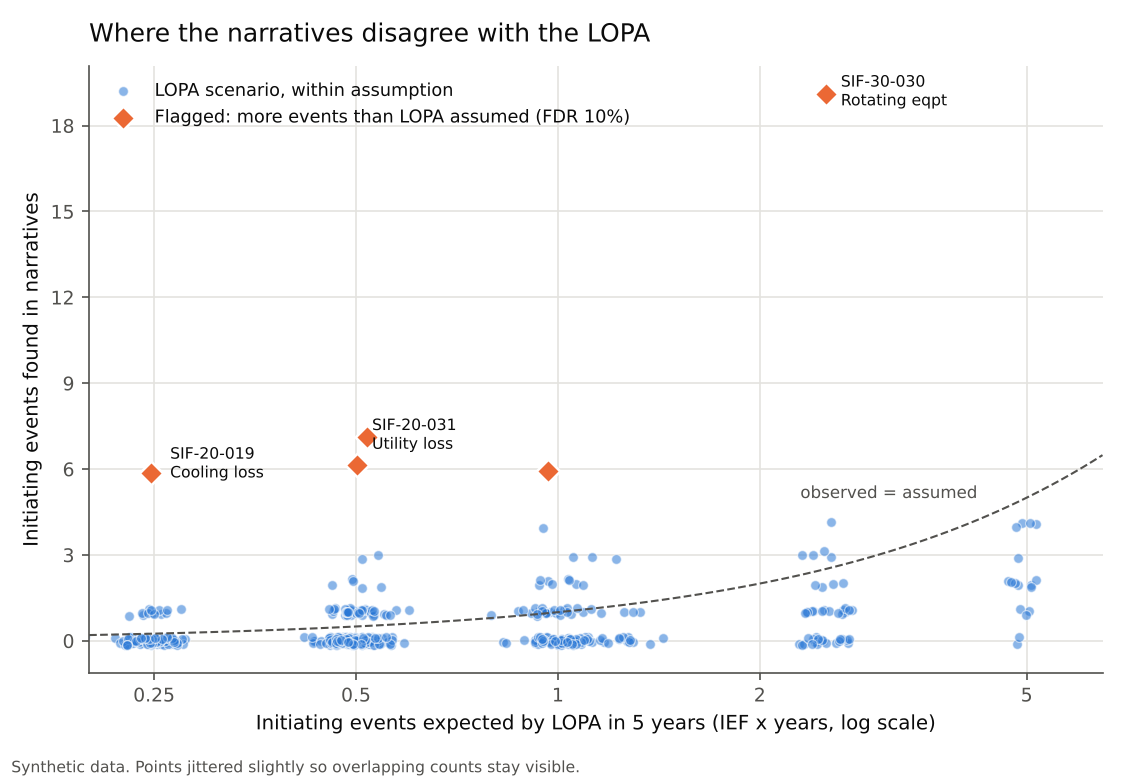

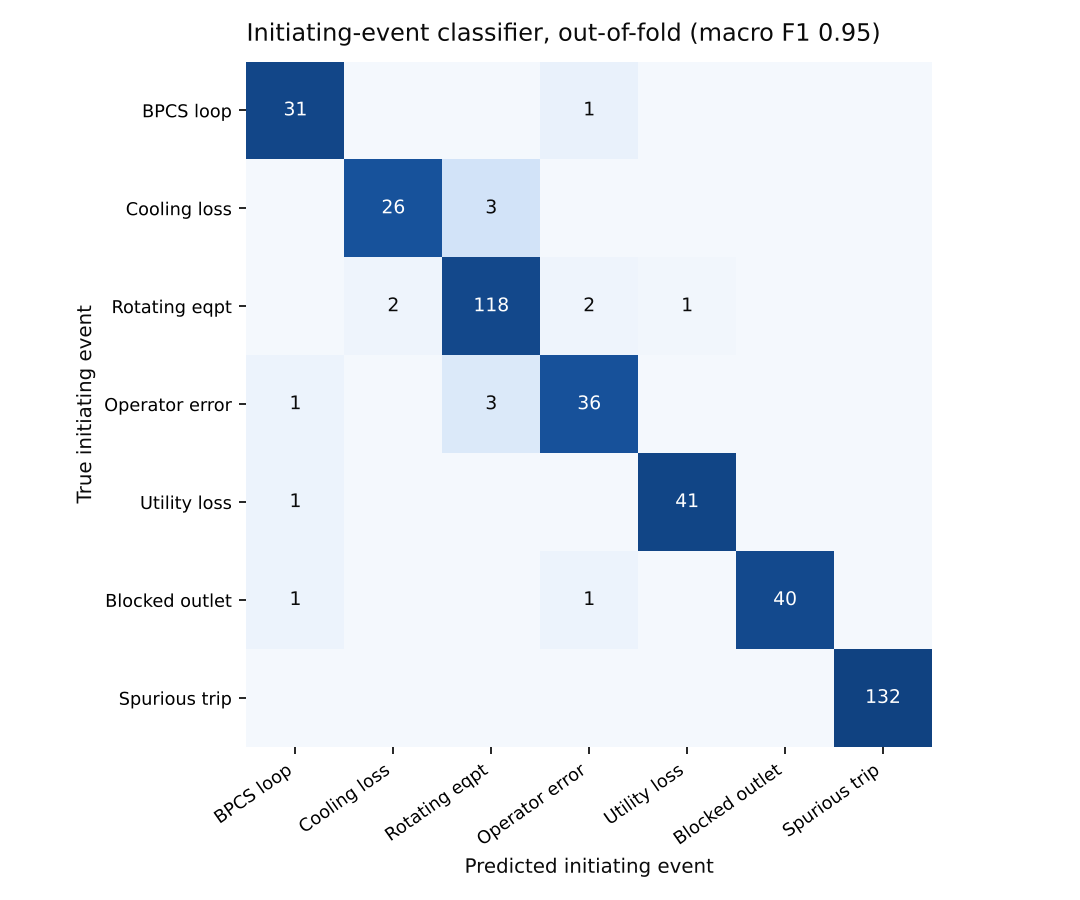

In [7]:
from IPython.display import Image, display
display(Image('reports/figures/observed_vs_lopa.png', width=700))
display(Image('reports/figures/confusion_matrix.png', width=560))

## 9. Serve it
`uvicorn src.api.app:app --reload`, then open http://127.0.0.1:8000/docs. The same call from Python:

In [8]:
from fastapi.testclient import TestClient
from src.models import train
train.train_and_save()
from src.api.app import app
TestClient(app).post('/analyse', json={'text': narr.text.iloc[3], 'unit': narr.unit.iloc[3]}).json()

{'sif_id': 'SIF-60-021',
 'link_method': 'sif_id',
 'link_note': '',
 'initiating_event': 'bpcs_loop_failure',
 'confidence': 0.484,
 'outcome': 'near_miss',
 'needs_review': True}